# 02. Baseline Demand Forecasting

## STEP 1 — IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error

## STEP 2 — LOAD PROCESSED DATA

In [2]:
# Define paths
DATA_DIR = Path('../data')
PROCESSED_DATA_PATH = DATA_DIR / 'processed_daily_sales.csv'

# Load the processed daily sales data
print("Loading data...")
df = pd.read_csv(PROCESSED_DATA_PATH)

# Parse Date as datetime
df['Date'] = pd.to_datetime(df['Date'])

print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print(f"\nNumber of products: {df['StockCode'].nunique()}")
print(f"Number of dates: {df['Date'].nunique()}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

print("\nMissing values:")
print(df.isnull().sum())

# Verify StockCode + Date is unique
is_unique = df.set_index(['StockCode', 'Date']).index.is_unique
print(f"\nIs 'StockCode + Date' unique?: {is_unique}")

Loading data...


C:\Users\ramganesh\AppData\Local\Temp\ipykernel_14476\1171878868.py:7: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(PROCESSED_DATA_PATH)


Shape: (1464584, 3)

First 5 rows:


,StockCode,Date,UnitsSold
0,10002,2010-12-01,12
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-04,0
4,10002,2010-12-05,1



Columns:
['StockCode', 'Date', 'UnitsSold']

Data Types:
StockCode            object
Date         datetime64[ns]
UnitsSold             int64
dtype: object

Number of products: 3918
Number of dates: 374
Date range: 2010-12-01 to 2011-12-09

Missing values:
StockCode    0
Date         0
UnitsSold    0
dtype: int64

Is 'StockCode + Date' unique?: True


## STEP 3 — SORT DATA

In [3]:
# Sort by StockCode and Date, then reset the index
df = df.sort_values(by=['StockCode', 'Date']).reset_index(drop=True)
print("Data sorted by StockCode and Date.")

Data sorted by StockCode and Date.


## STEP 4 — CREATE FUTURE 7-DAY TARGET
Given sales on date `T`, we want the sum of sales from `T+1` to `T+7`. Since our dataset has a complete calendar of dates for every product (including zeros), we can calculate this by looking ahead exactly 7 rows per product.

In [4]:
def calculate_future_demand(series):
    # Reverse the sales, take rolling sum of 7, reverse back, then shift by -1 to start at T+1
    return series.iloc[::-1].rolling(window=7, min_periods=7).sum().iloc[::-1].shift(-1)

df['Future7DayDemand'] = df.groupby('StockCode')['UnitsSold'].transform(calculate_future_demand)
print("Future 7-day target calculated.")

Future 7-day target calculated.


## STEP 5 — VALIDATE THE TARGET

In [5]:
# Create a tiny example dataset to prove the calculation is correct
example_df = pd.DataFrame({
    'StockCode': ['TEST'] * 8,
    'Date': pd.date_range(start='2023-01-01', periods=8),
    'UnitsSold': [10, 8, 5, 7, 6, 9, 4, 11]
})
example_df = example_df.sort_values(by=['StockCode', 'Date']).reset_index(drop=True)

example_df['Future7DayDemand'] = example_df.groupby('StockCode')['UnitsSold'].transform(calculate_future_demand)

print("Tiny Example Validation:")
display(example_df)

# Show one actual product
sample_product = df['StockCode'].unique()[0]
print(f"\nSample product from real data ({sample_product}):")
display(df[df['StockCode'] == sample_product][['StockCode', 'Date', 'UnitsSold', 'Future7DayDemand']].head(10))

Tiny Example Validation:


,StockCode,Date,UnitsSold,Future7DayDemand
0,TEST,2023-01-01,10,50.0
1,TEST,2023-01-02,8,NaN
2,TEST,2023-01-03,5,NaN
3,TEST,2023-01-04,7,NaN
4,TEST,2023-01-05,6,NaN
5,TEST,2023-01-06,9,NaN
6,TEST,2023-01-07,4,NaN
7,TEST,2023-01-08,11,NaN



Sample product from real data (21638):


,StockCode,Date,UnitsSold,Future7DayDemand
0,21638,2011-11-10,12,2.0
1,21638,2011-11-11,0,8.0
2,21638,2011-11-12,0,8.0
3,21638,2011-11-13,0,10.0
4,21638,2011-11-14,0,10.0
5,21638,2011-11-15,2,11.0
6,21638,2011-11-16,0,23.0
7,21638,2011-11-17,0,25.0
8,21638,2011-11-18,6,37.0
9,21638,2011-11-19,0,37.0


## STEP 6 — REMOVE ROWS WITHOUT A COMPLETE FUTURE TARGET
If fewer than seven future calendar days are available, the target cannot be calculated, resulting in `NaN`. We must remove these rows from the modeling dataset because supervised learning requires a known target for training and evaluation. We do not fill these with zero because predicting partial weeks or zeros for missing future days would misrepresent actual demand and bias the model.

In [6]:
print(f"Rows before dropping NaN targets: {len(df)}")
df = df.dropna(subset=['Future7DayDemand']).reset_index(drop=True)
print(f"Rows after dropping NaN targets: {len(df)}")

Rows before dropping NaN targets: 1464584
Rows after dropping NaN targets: 1437158


## STEP 7 — CHRONOLOGICAL TRAIN/TEST SPLIT
We will split the data chronologically, using the first ~80% of dates for training and the final ~20% for testing.

In [7]:
# Determine date split
dates = sorted(df['Date'].unique())
split_idx = int(len(dates) * 0.8)
split_date = dates[split_idx]

train_df = df[df['Date'] < split_date].copy()
test_df = df[df['Date'] >= split_date].copy()

print(f"Training start: {train_df['Date'].min().date()}")
print(f"Training end:   {train_df['Date'].max().date()}")
print(f"Testing start:  {test_df['Date'].min().date()}")
print(f"Testing end:    {test_df['Date'].max().date()}")

print(f"\nTraining rows: {len(train_df)}")
print(f"Testing rows:  {len(test_df)}")

print(f"\nUnique products in Train: {train_df['StockCode'].nunique()}")
print(f"Unique products in Test:  {test_df['StockCode'].nunique()}")

# Unseen test products
train_products = set(train_df['StockCode'].unique())
test_products = set(test_df['StockCode'].unique())
unseen_products = test_products - train_products
print(f"Number of unseen products in Test: {len(unseen_products)}")

Training start: 2010-12-01
Training end:   2011-09-19
Testing start:  2011-09-20
Testing end:    2011-12-02

Training rows: 1147381
Testing rows:  289777

Unique products in Train: 3917
Unique products in Test:  3917
Number of unseen products in Test: 1


## LEVEL 0 BASELINE
Global Mean Baseline: Predict the same demand value for every test observation using the average future 7-day demand in the training set.

In [8]:
# Calculate global training mean
global_mean_target = train_df['Future7DayDemand'].mean()

# Predict on test set
test_df['Level0_Prediction'] = global_mean_target

# Evaluate
level0_mae = mean_absolute_error(test_df['Future7DayDemand'], test_df['Level0_Prediction'])

print("Level 0 Baseline")
print("----------------")
print(f"Training mean: {global_mean_target:.4f}")
print(f"Test MAE: {level0_mae:.4f}")

Level 0 Baseline
----------------
Training mean: 18.3150
Test MAE: 39.1022


## LEVEL 1 BASELINE
**Product Historical Mean Baseline**: Predict each product's future 7-day demand using that product's historical average 7-day demand in the training set. For products not in the training set, fall back to the global training mean.

This is a simple product-aware baseline that significantly improves upon the global mean by incorporating product-specific historical behavior.

In [9]:
# Calculate product-specific mean target in training data
product_means = train_df.groupby('StockCode')['Future7DayDemand'].mean().to_dict()

# Predict on test set (mapping product mean, falling back to global mean if unseen)
test_df['Level1_Prediction'] = test_df['StockCode'].map(product_means).fillna(global_mean_target)

# Evaluate
level1_mae = mean_absolute_error(test_df['Future7DayDemand'], test_df['Level1_Prediction'])

print("Level 1 Baseline (Product Historical Mean)")
print("------------------------------------------")
print(f"Test MAE: {level1_mae:.4f}")

Level 1 Baseline (Product Historical Mean)
------------------------------------------
Test MAE: 28.5688


## BASELINE COMPARISON

In [10]:
improvement_pct = ((level0_mae - level1_mae) / level0_mae) * 100

print(f"{'Model':<35} MAE")
print("-" * 45)
print(f"{'Level 0 — Global Mean':<35} {level0_mae:.4f}")
print(f"{'Level 1 — Product Mean':<35} {level1_mae:.4f}")
print("-" * 45)
print(f"Improvement (%): {improvement_pct:.2f}%")

print(f"\nInterpretation: Level 1 improves over Level 0 by {improvement_pct:.2f}%, indicating that product-specific historical behavior provides useful information for demand estimation.")

Model                               MAE
---------------------------------------------
Level 0 — Global Mean               39.1022
Level 1 — Product Mean              28.5688
---------------------------------------------
Improvement (%): 26.94%

Interpretation: Level 1 improves over Level 0 by 26.94%, indicating that product-specific historical behavior provides useful information for demand estimation.


## BASELINE VISUALIZATION

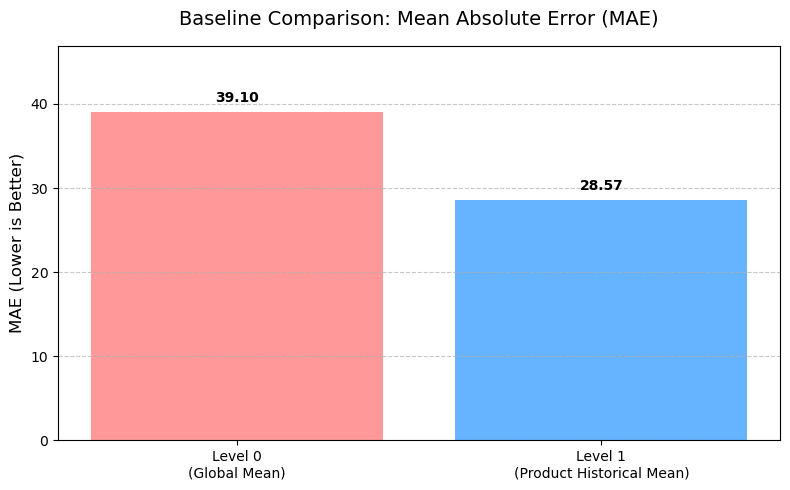

In [11]:
plt.figure(figsize=(8, 5))
models = ['Level 0\n(Global Mean)', 'Level 1\n(Product Historical Mean)']
maes = [level0_mae, level1_mae]

bars = plt.bar(models, maes, color=['#ff9999', '#66b3ff'])

# Add text labels on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02 * max(maes), f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')

plt.title('Baseline Comparison: Mean Absolute Error (MAE)', fontsize=14, pad=15)
plt.ylabel('MAE (Lower is Better)', fontsize=12)
plt.ylim(0, max(maes) * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## FINAL NOTEBOOK OUTPUT

In [12]:
print("========================================")
print("BASELINE RESULTS")
print("========================================")
print("\nTarget:")
print("Future 7-Day Product Demand")

print(f"\nTraining Period:")
print(f"{train_df['Date'].min().date()} to {train_df['Date'].max().date()}")

print(f"\nTesting Period:")
print(f"{test_df['Date'].min().date()} to {test_df['Date'].max().date()}")

print(f"\nTraining Rows:")
print(f"{len(train_df)}")

print(f"\nTesting Rows:")
print(f"{len(test_df)}")

print("\nLevel 0 — Global Mean")
print(f"MAE: {level0_mae:.4f}")

print("\nLevel 1 — Product Historical Mean")
print(f"MAE: {level1_mae:.4f}")

print("\nImprovement:")
print(f"{improvement_pct:.2f} %")

print("\nNext Step:")
print("Feature Engineering → Random Forest")

BASELINE RESULTS

Target:
Future 7-Day Product Demand

Training Period:
2010-12-01 to 2011-09-19

Testing Period:
2011-09-20 to 2011-12-02

Training Rows:
1147381

Testing Rows:
289777

Level 0 — Global Mean
MAE: 39.1022

Level 1 — Product Historical Mean
MAE: 28.5688

Improvement:
26.94 %

Next Step:
Feature Engineering → Random Forest
